In [1]:
!uv pip install duckdb pandas numpy matplotlib seaborn langgraph langchain-openai langchain-core openai python-dotenv
!uv pip install tabulate
!uv pip install fpdf2 markdown2 pillow
!uv pip install reportlab


Using Python 3.12.10 environment at: C:\Users\eugen\Documents\.venv-cuda312
Checked 10 packages in 500ms
Using Python 3.12.10 environment at: C:\Users\eugen\Documents\.venv-cuda312
Resolved 1 package in 2.77s
Prepared 1 package in 517ms
Installed 1 package in 14ms
 + tabulate==0.10.0
Using Python 3.12.10 environment at: C:\Users\eugen\Documents\.venv-cuda312
Resolved 4 packages in 3.20s
Prepared 2 packages in 1.20s
Installed 2 packages in 67ms
 + fpdf2==2.9.0
 + markdown2==2.5.5
Using Python 3.12.10 environment at: C:\Users\eugen\Documents\.venv-cuda312
Resolved 3 packages in 2.64s
 Downloaded reportlab
Prepared 1 package in 2.22s
Installed 1 package in 87ms
 + reportlab==5.1.0


In [5]:
%pip install python-dotenv

Note: you may need to restart the kernel to use updated packages.


In [ ]:
# Importações necessárias
import os
import duckdb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from typing import TypedDict, List, Dict, Any
from langgraph.graph import StateGraph, START, END
from langchain_openai.chat_models import ChatOpenAI
from langchain_core.prompts import ChatPromptTemplate
from dotenv import load_dotenv

#0)import os
from dotenv import load_dotenv
from langchain_openai import ChatOpenAI

import os
from langchain_openai import ChatOpenAI

os.environ["OPENAI_API_KEY"] = "sk-proj"

llm = ChatOpenAI(
    model="gpt-4o",
    temperature=0
)

resposta = llm.invoke("Olá, você está funcionando?")
print(resposta.content)

Olá! Sim, estou funcionando. Como posso ajudar você hoje?


In [2]:
# Criar um banco de dados fictício em memória
conn = duckdb.connect(database=':memory:')

# Criar dados fictícios mais robustos (2000 registros)
import numpy as np
import random
from datetime import datetime, timedelta

# Lista de produtos expandida
produtos = [
    'Smartphone Galaxy', 'Notebook Dell', 'Monitor LG', 'Teclado Mecânico', 
    'Mouse Gamer', 'Headset Bluetooth', 'Tablet iPad', 'Smartwatch Apple',
    'Câmera DSLR', 'Impressora HP', 'Roteador WiFi', 'SSD 1TB',
    'Memória RAM 16GB', 'Placa de Vídeo RTX', 'Processador Intel i7',
    'Caixa de Som JBL', 'Fone de Ouvido Sony', 'Carregador Portátil',
    'Cabo HDMI', 'Adaptador USB-C'
]

# Gerar 2000 registros
num_registros = 2000
start_date = datetime(2023, 1, 1)

# Criar dados
sales_data = pd.DataFrame({
    'order_id': range(1, num_registros + 1),
    'date': [start_date + timedelta(days=random.randint(0, 365)) for _ in range(num_registros)],
    'customer_id': [f'C{str(random.randint(1, 500)).zfill(3)}' for _ in range(num_registros)],
    'product': [random.choice(produtos) for _ in range(num_registros)],
    'quantity': np.random.randint(1, 20, size=num_registros),
    'price': np.random.uniform(10.0, 1000.0, size=num_registros),
    'region': [random.choice(['Norte', 'Sul', 'Leste', 'Oeste', 'Centro']) for _ in range(num_registros)],
    'payment_method': [random.choice(['Cartão de Crédito', 'Boleto', 'PIX', 'Transferência']) for _ in range(num_registros)]
})

# Adicionar coluna de valor total
sales_data['total_value'] = sales_data['quantity'] * sales_data['price']

# Criar a tabela no DuckDB
conn.execute("CREATE TABLE sales AS SELECT * FROM sales_data")

In [3]:
# Verificar o número de registros
result = conn.execute("SELECT COUNT(*) AS total_registros FROM sales").fetchall()
print(f"Total de registros na tabela: {result[0][0]}")

# Verificar a distribuição de produtos
product_distribution = conn.execute("""
    SELECT 
        product, 
        COUNT(*) as quantidade 
    FROM sales 
    GROUP BY product 
    ORDER BY quantidade DESC
""").df()

print("\nDistribuição de produtos:")
print(product_distribution)

Total de registros na tabela: 2000

Distribuição de produtos:
                 product  quantidade
0          Impressora HP         116
1        Adaptador USB-C         112
2            Tablet iPad         107
3    Fone de Ouvido Sony         107
4          Roteador WiFi         107
5            Mouse Gamer         105
6      Headset Bluetooth         103
7       Memória RAM 16GB         103
8       Teclado Mecânico         103
9       Smartwatch Apple         100
10            Monitor LG         100
11     Smartphone Galaxy          99
12  Processador Intel i7          99
13      Caixa de Som JBL          99
14         Notebook Dell          99
15   Carregador Portátil          97
16             Cabo HDMI          92
17               SSD 1TB          90
18           Câmera DSLR          89
19    Placa de Vídeo RTX          73


In [4]:
# Query para verificar o número total de registros
verification_query = """
SELECT 
    COUNT(*) AS total_registros,
    COUNT(DISTINCT product) AS total_produtos,
    MIN(date) AS data_mais_antiga,
    MAX(date) AS data_mais_recente,
    SUM(total_value) AS valor_total_vendas
FROM sales
"""

verification_result = conn.execute(verification_query).df()
print("\nVerificação do banco de dados:")
print(verification_result)

# Mostrar alguns registros de exemplo
sample_query = "SELECT * FROM sales LIMIT 10"
sample_result = conn.execute(sample_query).df()
print("\nExemplo de registros:")
print(sample_result)


Verificação do banco de dados:
   total_registros  total_produtos data_mais_antiga data_mais_recente  \
0             2000              20       2023-01-01        2024-01-01   

   valor_total_vendas  
0        1.024563e+07  

Exemplo de registros:
   order_id       date customer_id              product  quantity       price  \
0         1 2023-02-10        C409     Memória RAM 16GB        18  161.547318   
1         2 2023-02-24        C256     Caixa de Som JBL        11  839.249308   
2         3 2023-04-06        C238     Teclado Mecânico        13  460.142423   
3         4 2023-07-22        C193   Placa de Vídeo RTX        13  819.220646   
4         5 2023-09-17        C128  Carregador Portátil        14  550.342454   
5         6 2023-01-24        C463      Adaptador USB-C        11  653.090876   
6         7 2023-09-19        C009            Cabo HDMI        18  369.094439   
7         8 2023-08-07        C423        Roteador WiFi        17  528.979096   
8         9 2023-05-1

In [5]:
# Estruturas de dados
class State(TypedDict):
    user_request: str
    sql_query: str
    query_result: pd.DataFrame
    report: str
    visualization: Any
    errors: List[str]

In [6]:
def parse_user_request(state: State) -> State:
    """
    Converte a solicitação do usuário em uma consulta SQL.
    """
    user_request = state['user_request']
    
    prompt = ChatPromptTemplate.from_template(
        """
Você é um assistente que cria consultas SQL com base em solicitações em linguagem natural.
A partir da solicitação abaixo, gere uma consulta SQL válida para o banco de dados fornecido.

Solicitação do usuário:
{user_request}

Tabelas disponíveis e seus esquemas:

Tabela 'sales':
- order_id (INTEGER)
- date (DATE)
- customer_id (VARCHAR)
- product (VARCHAR)
- quantity (INTEGER)
- price (FLOAT)
- region (VARCHAR)
- payment_method (VARCHAR)
- total_value (FLOAT)

Importante:
- Use apenas as tabelas e colunas fornecidas.
- Certifique-se de que a consulta seja compatível com o DuckDB.
- Retorne apenas a consulta SQL pura, sem marcadores markdown ou decorações.
- Não use ``` ou sql em sua resposta.
        """
    )
    
    response = llm.invoke(prompt.format(user_request=user_request))
    sql_query = response.content.strip()
    
    # Limpar marcadores markdown se ainda estiverem presentes
    sql_query = sql_query.replace('```sql', '').replace('```', '').strip()
    
    state['sql_query'] = sql_query
    return state

In [7]:
def execute_sql_query(state: State) -> State:
    """
    Executa a consulta SQL e armazena o resultado.
    """
    sql_query = state.get('sql_query', '')
    try:
        query_result = conn.execute(sql_query).df()
        state['query_result'] = query_result
    except Exception as e:
        state['errors'].append(f"Erro ao executar a consulta SQL: {e}")
    return state

In [8]:
def generate_visualization(state: State) -> State:
    """
    Gera visualizações com base nos dados obtidos.
    """
    query_result = state.get('query_result')
    if query_result is None or query_result.empty:
        state['errors'].append("Nenhum dado disponível para gerar visualização.")
        return state
    
    try:
        plt.figure(figsize=(10, 6))
        
        # Determinar o tipo de visualização com base nas colunas disponíveis
        if 'product' in query_result.columns and any(col in query_result.columns for col in ['total_value', 'quantity', 'price']):
            # Gráfico de barras para produtos
            value_col = next((col for col in ['total_value', 'quantity', 'price'] if col in query_result.columns), None)
            if value_col:
                sns.barplot(data=query_result, x='product', y=value_col)
                plt.title(f'{value_col.replace("_", " ").title()} por Produto')
                plt.xlabel('Produto')
                plt.ylabel(value_col.replace("_", " ").title())
                plt.xticks(rotation=45)
        
        elif 'region' in query_result.columns and any(col in query_result.columns for col in ['total_value', 'quantity']):
            # Gráfico de barras para regiões
            value_col = next((col for col in ['total_value', 'quantity'] if col in query_result.columns), None)
            if value_col:
                sns.barplot(data=query_result, x='region', y=value_col)
                plt.title(f'{value_col.replace("_", " ").title()} por Região')
                plt.xlabel('Região')
                plt.ylabel(value_col.replace("_", " ").title())
        
        elif 'payment_method' in query_result.columns and 'total_value' in query_result.columns:
            # Gráfico de pizza para métodos de pagamento
            plt.pie(query_result['total_value'], labels=query_result['payment_method'], autopct='%1.1f%%')
            plt.title('Distribuição de Vendas por Método de Pagamento')
        
        elif 'date' in query_result.columns and any(col in query_result.columns for col in ['total_value', 'quantity']):
            # Gráfico de linha para tendência temporal
            value_col = next((col for col in ['total_value', 'quantity'] if col in query_result.columns), None)
            if value_col:
                plt.plot(query_result['date'], query_result[value_col])
                plt.title(f'Tendência de {value_col.replace("_", " ").title()} ao Longo do Tempo')
                plt.xlabel('Data')
                plt.ylabel(value_col.replace("_", " ").title())
                plt.xticks(rotation=45)
        
        plt.tight_layout()
        state['visualization'] = plt.gcf()
        
    except Exception as e:
        state['errors'].append(f"Erro ao gerar visualização: {str(e)}")
    
    return state

In [9]:
def generate_report(state: State) -> State:
    """
    Gera o relatório final com base nos dados e visualizações.
    """
    query_result = state.get('query_result')
    visualization = state.get('visualization')
    
    if query_result is None or query_result.empty:
        state['errors'].append("Nenhum dado disponível para gerar o relatório.")
        return state
    
    try:
        # Gerar um resumo dos dados
        num_rows = len(query_result)
        
        report = f"# Relatório Gerado com Base na Solicitação\n\n"
        report += f"**Solicitação original:** {state['user_request']}\n\n"
        report += f"**Consulta SQL executada:**\n```sql\n{state['sql_query']}\n```\n\n"
        
        report += f"## Resumo dos Dados\n\n"
        report += f"- Total de registros: {num_rows}\n"
        
        # Adicionar estatísticas específicas com base nas colunas disponíveis
        if 'total_value' in query_result.columns:
            total_value = query_result['total_value'].sum()
            avg_value = query_result['total_value'].mean()
            report += f"- Valor total: R$ {total_value:.2f}\n"
            report += f"- Valor médio: R$ {avg_value:.2f}\n"
        
        if 'product' in query_result.columns and query_result['product'].nunique() < 10:
            report += f"- Produtos incluídos: {', '.join(query_result['product'].unique())}\n"
        
        if 'region' in query_result.columns and query_result['region'].nunique() < 10:
            report += f"- Regiões incluídas: {', '.join(query_result['region'].unique())}\n"
        
        # Adicionar tabela de dados
        report += f"\n## Dados Detalhados\n\n"
        
        # Limitar a 10 linhas para não sobrecarregar o relatório
        sample_data = query_result.head(10)
        report += sample_data.to_markdown() + "\n"
        
        if len(query_result) > 10:
            report += f"\n*Mostrando 10 de {len(query_result)} registros*\n"
        
        state['report'] = report
    except Exception as e:
        state['errors'].append(f"Erro ao gerar relatório: {str(e)}")
    
    return state

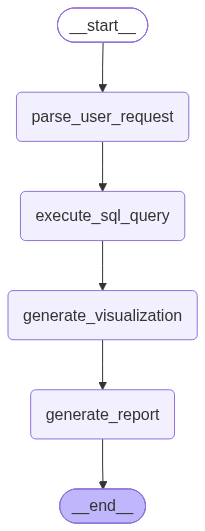

In [10]:
#### TEstando a ferramenta com erros 
# Inicializar o grafo de estado
workflow = StateGraph(State)

# Adicionar nós
workflow.add_node("parse_user_request", parse_user_request)
workflow.add_node("execute_sql_query", execute_sql_query)
workflow.add_node("generate_visualization", generate_visualization)
workflow.add_node("generate_report", generate_report)

# Definir as arestas
workflow.add_edge(START, "parse_user_request")
workflow.add_edge("parse_user_request", "execute_sql_query")
workflow.add_edge("execute_sql_query", "generate_visualization")
workflow.add_edge("generate_visualization", "generate_report")
workflow.add_edge("generate_report", END)

# Compilar o grafo
app = workflow.compile()

# Visualizar o grafo (opcional)
from IPython.display import Image, display
display(Image(app.get_graph().draw_mermaid_png()))

In [11]:
def generate_business_report(user_request: str):
    """
    Gera um relatório empresarial com base na solicitação do usuário.
    
    Args:
        user_request (str): Solicitação em linguagem natural.
    
    Returns:
        State: Estado final após o processamento.
    """
    initial_state = State(
        user_request=user_request,
        sql_query='',
        query_result=None,
        report='',
        visualization=None,
        errors=[]
    )
    final_state = app.invoke(initial_state)
    return final_state

# Teste com um exemplo
user_request = "Mostre o total de vendas por produto, ordenado do maior para o menor valor"

# Executar o fluxo
final_state = generate_business_report(user_request)

# Verificar o resultado
print("SQL Query gerada:")
print(final_state['sql_query'])
print("\n" + "-"*50 + "\n")

if final_state['errors']:
    print("Erros encontrados:")
    for error in final_state['errors']:
        print(f"- {error}")
else:
    print("Relatório:")
    print(final_state['report'])
    
    if final_state.get('visualization'):
        try:
            plt.figure(final_state['visualization'].number)
            plt.show()
        except Exception as e:
            print(f"Erro ao mostrar visualização: {e}")

SQL Query gerada:
SELECT product, SUM(total_value) AS total_sales
FROM sales
GROUP BY product
ORDER BY total_sales DESC;

--------------------------------------------------

Relatório:
# Relatório Gerado com Base na Solicitação

**Solicitação original:** Mostre o total de vendas por produto, ordenado do maior para o menor valor

**Consulta SQL executada:**
```sql
SELECT product, SUM(total_value) AS total_sales
FROM sales
GROUP BY product
ORDER BY total_sales DESC;
```

## Resumo dos Dados

- Total de registros: 20

## Dados Detalhados

|    | product             |   total_sales |
|---:|:--------------------|--------------:|
|  0 | Adaptador USB-C     |        643085 |
|  1 | Fone de Ouvido Sony |        588322 |
|  2 | Monitor LG          |        566853 |
|  3 | Tablet iPad         |        560694 |
|  4 | Impressora HP       |        557783 |
|  5 | Smartwatch Apple    |        552102 |
|  6 | Memória RAM 16GB    |        550786 |
|  7 | Roteador WiFi       |        526288 |
|  8 | T

<Figure size 1000x600 with 0 Axes>

In [12]:
import matplotlib
matplotlib.use('Agg')  # Use o backend Agg para evitar problemas com o display
import matplotlib.pyplot as plt
from reportlab.lib.pagesizes import letter
from reportlab.lib import colors
from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle, PageBreak
from reportlab.lib.styles import getSampleStyleSheet
from reportlab.lib.units import inch
import io
import re
from reportlab.platypus import Image as ReportLabImage

def generate_multi_query_report(queries, filename="relatorio_multiplo.pdf", title="Relatório Analítico Consolidado"):
    """
    Gera um relatório PDF contendo múltiplas consultas e suas visualizações.
    
    Args:
        queries (list): Lista de strings com as consultas em linguagem natural.
        filename (str): Nome do arquivo PDF a ser gerado.
        title (str): Título principal do relatório.
    
    Returns:
        list: Lista dos estados finais de cada consulta.
    """
    # Criar documento PDF
    doc = SimpleDocTemplate(filename, pagesize=letter)
    styles = getSampleStyleSheet()
    
    # Usar estilos existentes
    title_style = styles['Title']
    title_style.alignment = 1  # Centralizado
    
    heading1_style = styles['Heading1']
    heading2_style = styles['Heading2']
    normal_style = styles['Normal']
    
    # Lista de elementos para o PDF
    elements = []
    
    # Adicionar título principal
    elements.append(Paragraph(title, title_style))
    elements.append(Spacer(1, 0.5*inch))
    
    # Lista para armazenar os estados finais
    final_states = []
    
    # Processar cada consulta
    for i, query in enumerate(queries):
        print(f"Processando consulta {i+1}/{len(queries)}: {query}")
        
        # Gerar relatório para esta consulta
        state = generate_business_report(query)
        final_states.append(state)
        
        if state['errors']:
            print(f"Erros na consulta {i+1}:")
            for error in state['errors']:
                print(f"- {error}")
            continue
        
        # Adicionar título da seção (número da consulta)
        elements.append(Paragraph(f"Análise {i+1}: {query}", heading1_style))
        elements.append(Spacer(1, 0.25*inch))
        
        # Processar o relatório
        report_text = state['report']
        
        # Extrair a consulta SQL
        sql_match = re.search(r'\*\*Consulta SQL executada:\*\*\n```sql\n(.*?)\n```', report_text, re.DOTALL)
        if sql_match:
            elements.append(Paragraph("<b>Consulta SQL executada:</b>", normal_style))
            sql_code = sql_match.group(1)
            elements.append(Paragraph(f"<font face='Courier'>{sql_code}</font>", normal_style))
            elements.append(Spacer(1, 0.1*inch))
        
        # Adicionar resumo dos dados
        elements.append(Paragraph("Resumo dos Dados", heading2_style))
        
        # Extrair itens do resumo
        summary_section = re.search(r'## Resumo dos Dados\n\n(.*?)(?=\n\n##|\Z)', report_text, re.DOTALL)
        if summary_section:
            summary_items = re.findall(r'- (.*?)\n', summary_section.group(1))
            for item in summary_items:
                elements.append(Paragraph(f"• {item}", normal_style))
        
        elements.append(Spacer(1, 0.2*inch))
        
        # Adicionar dados detalhados
        elements.append(Paragraph("Dados Detalhados", heading2_style))
        
        # Extrair tabela de dados
        if state.get('query_result') is not None and not state['query_result'].empty:
            df = state['query_result'].head(10)
            
            # Criar tabela
            table_data = [df.columns.tolist()]  # Cabeçalho
            for i, row in df.iterrows():
                table_data.append([str(x) for x in row.tolist()])
            
            # Formatar a tabela
            table = Table(table_data, repeatRows=1)
            table.setStyle(TableStyle([
                ('BACKGROUND', (0, 0), (-1, 0), colors.lightgrey),
                ('TEXTCOLOR', (0, 0), (-1, 0), colors.black),
                ('ALIGN', (0, 0), (-1, -1), 'CENTER'),
                ('FONTNAME', (0, 0), (-1, 0), 'Helvetica-Bold'),
                ('FONTSIZE', (0, 0), (-1, 0), 10),
                ('BOTTOMPADDING', (0, 0), (-1, 0), 12),
                ('BACKGROUND', (0, 1), (-1, -1), colors.white),
                ('GRID', (0, 0), (-1, -1), 1, colors.black),
                ('FONTNAME', (0, 1), (-1, -1), 'Helvetica'),
                ('FONTSIZE', (0, 1), (-1, -1), 9),
            ]))
            
            elements.append(table)
            
            if len(state['query_result']) > 10:
                elements.append(Paragraph(f"*Mostrando 10 de {len(state['query_result'])} registros*", normal_style))
        
        # Adicionar visualização criada a partir dos dados brutos
        if state.get('query_result') is not None and not state['query_result'].empty:
            try:
                elements.append(Spacer(1, 0.3*inch))
                elements.append(Paragraph("Visualização", heading2_style))
                
                # Criar uma nova figura
                plt.figure(figsize=(10, 6))
                
                # Determinar o tipo de gráfico com base no relatório
                df = state['query_result']
                
                # Limitar a 10 itens para melhor visualização
                if len(df) > 10:
                    df = df.head(10)
                
                # Determinar colunas para x e y
                if len(df.columns) >= 2:
                    x_col = df.columns[0]
                    y_col = df.columns[1]
                    
                    # Verificar se a solicitação sugere um tipo específico de gráfico
                    if "pizza" in query.lower() or "pie" in query.lower():
                        plt.figure(figsize=(8, 8))
                        plt.pie(df[y_col], labels=df[x_col], autopct='%1.1f%%')
                        plt.axis('equal')  # Equal aspect ratio ensures that pie is drawn as a circle
                    elif "barra" in query.lower() or "bar" in query.lower():
                        plt.bar(df[x_col], df[y_col])
                        plt.xticks(rotation=45, ha='right')
                    else:
                        # Verificar se os dados são numéricos para decidir o tipo de gráfico
                        if df[x_col].dtype.kind in 'ifc' and df[y_col].dtype.kind in 'ifc':
                            # Ambos são numéricos, usar gráfico de dispersão
                            plt.scatter(df[x_col], df[y_col])
                        else:
                            # Usar gráfico de barras como padrão
                            plt.bar(df[x_col], df[y_col])
                            plt.xticks(rotation=45, ha='right')
                    
                    plt.title(query)
                    plt.xlabel(x_col)
                    plt.ylabel(y_col)
                    plt.tight_layout()
                    
                    # Salvar a figura em um buffer de memória
                    img_data = io.BytesIO()
                    plt.savefig(img_data, format='png', dpi=300)
                    img_data.seek(0)
                    
                    # Criar uma imagem para o ReportLab
                    img = ReportLabImage(img_data, width=6*inch, height=4*inch)
                    elements.append(img)
                    
                    # Fechar a figura para liberar memória
                    plt.close()
                
            except Exception as e:
                print(f"Erro ao criar visualização: {str(e)}")
                elements.append(Paragraph(f"Erro ao adicionar visualização: {str(e)}", normal_style))
        
        # Adicionar quebra de página após cada consulta (exceto a última)
        if i < len(queries) - 1:
            elements.append(PageBreak())
    
    # Construir o PDF
    try:
        doc.build(elements)
        print(f"Relatório múltiplo salvo como {filename}")
    except Exception as e:
        print(f"Erro ao gerar PDF: {str(e)}")
    
    return final_states

In [13]:
# Lista de consultas para incluir no relatório
queries = [
    "Quais são os 5 produtos mais vendidos em termos de valor total?",
    "Como se comparam as vendas totais entre as diferentes regiões?",
    "Qual é a distribuição percentual dos métodos de pagamento utilizados? Apresente em um gráfico de pizza",
    "Mostre a evolução das vendas mensais ao longo de 2023"
]

# Gerar o relatório múltiplo
generate_multi_query_report(queries, "relatorio_consolidado.pdf", "Análise Completa de Vendas 2023")

Processando consulta 1/4: Quais são os 5 produtos mais vendidos em termos de valor total?
Processando consulta 2/4: Como se comparam as vendas totais entre as diferentes regiões?
Processando consulta 3/4: Qual é a distribuição percentual dos métodos de pagamento utilizados? Apresente em um gráfico de pizza
Processando consulta 4/4: Mostre a evolução das vendas mensais ao longo de 2023
Relatório múltiplo salvo como relatorio_consolidado.pdf


[{'user_request': 'Quais são os 5 produtos mais vendidos em termos de valor total?',
  'sql_query': 'SELECT product, SUM(total_value) AS total_sales_value\nFROM sales\nGROUP BY product\nORDER BY total_sales_value DESC\nLIMIT 5;',
  'query_result':                product  total_sales_value
  0      Adaptador USB-C      643085.359883
  1  Fone de Ouvido Sony      588322.363239
  2           Monitor LG      566853.138985
  3          Tablet iPad      560694.017385
  4        Impressora HP      557783.115825,
  'report': '# Relatório Gerado com Base na Solicitação\n\n**Solicitação original:** Quais são os 5 produtos mais vendidos em termos de valor total?\n\n**Consulta SQL executada:**\n```sql\nSELECT product, SUM(total_value) AS total_sales_value\nFROM sales\nGROUP BY product\nORDER BY total_sales_value DESC\nLIMIT 5;\n```\n\n## Resumo dos Dados\n\n- Total de registros: 5\n- Produtos incluídos: Adaptador USB-C, Fone de Ouvido Sony, Monitor LG, Tablet iPad, Impressora HP\n\n## Dados Detalh

In [14]:
queries = [
    "Qual a quantidade de produtos por categoria?",
    "Qual o preço médio dos produtos por categoria?",
    "Qual a quantidade total de clientes?",
    "Quais são os produtos mais caros?",
    "Qual a quantidade de pedidos por categoria?"
]

resultados = generate_multi_query_report(
    queries,
    filename="relatorio_multiplo.pdf",
    title="Relatório Analítico de E-commerce"
)

Processando consulta 1/5: Qual a quantidade de produtos por categoria?
Processando consulta 2/5: Qual o preço médio dos produtos por categoria?
Processando consulta 3/5: Qual a quantidade total de clientes?
Processando consulta 4/5: Quais são os produtos mais caros?
Processando consulta 5/5: Qual a quantidade de pedidos por categoria?
Relatório múltiplo salvo como relatorio_multiplo.pdf


In [ ]:
from IPython.display import display, IFrame, FileLink
from pathlib import Path

arquivo = Path("relatorio_multiplo.pdf")

if arquivo.exists() and arquivo.stat().st_size > 0:
    print("PDF gerado:", arquivo.resolve())

    display(FileLink(str(arquivo)))

    display(
        IFrame(
            src=str(arquivo),
            width=900,
            height=600
        )
    )
else:
    print("O PDF não foi gerado.")

PDF gerado: C:\Users\eugen\Desktop\Kiro\relatorio_multiplo.pdf


c:\Users\eugen\Desktop\Kiro\relatorio_multiplo.pdf